In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
dataset = pd.read_csv("email.csv")

print("Dataset loaded successfully!")

print("Shape:", dataset.shape)

dataset.head()

Dataset loaded successfully!
Shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [6]:
# Display dataset information
dataset.info()

# Check missing values
print("\nMissing Values:")
print(dataset.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:", dataset.duplicated().sum())

# Display column names
print("\nColumns:")
print(dataset.columns.tolist())

# Statistical summary
dataset.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB

Missing Values:
0

Duplicate Records: 0

Columns:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [7]:
print(dataset.iloc[:, -5:].head())

   military  allowing  ff  dry  Prediction
0         0         0   0    0           0
1         0         0   1    0           0
2         0         0   0    0           0
3         0         0   0    0           0
4         0         0   1    0           0


In [8]:
# Remove duplicate records
dataset.drop_duplicates(inplace=True)

# Remove unnecessary ID column
dataset.drop(
    columns=['Email No.'],
    errors='ignore',
    inplace=True
)

# Remove missing target values
dataset.dropna(subset=['Prediction'], inplace=True)

# Fill missing feature values
dataset.fillna(0, inplace=True)

# Separate independent and dependent variables
X = dataset.drop('Prediction', axis=1)

Y = dataset['Prediction'].astype(int)

print("Preprocessing completed!")

print("Features shape:", X.shape)
print("Target shape:", Y.shape)

print("\nClass Distribution:")
print(Y.value_counts())

Preprocessing completed!
Features shape: (5172, 3000)
Target shape: (5172,)

Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


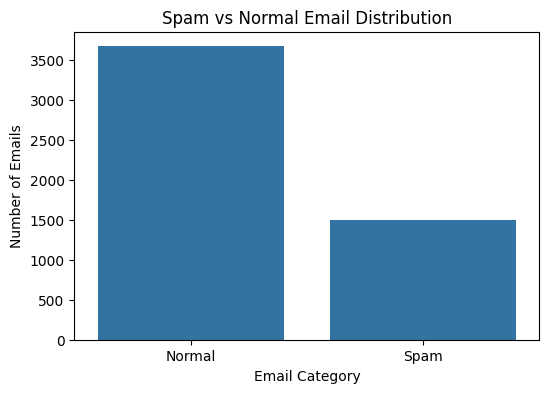

In [9]:
plt.figure(figsize=(6, 4))

sns.countplot(x=Y)

plt.title("Spam vs Normal Email Distribution")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

plt.xticks([0, 1], ['Normal', 'Spam'])

plt.show()

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4137, 3000)
Testing data: (1035, 3000)


In [11]:
# Create KNN model with feature scaling
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, Y_train)

# Predict test data
knn_predictions = knn_model.predict(X_test)

print("KNN Model trained successfully!")

KNN Model trained successfully!


In [12]:
# Create SVM model with feature scaling
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='linear'))
])

# Train the model
svm_model.fit(X_train, Y_train)

# Predict test data
svm_predictions = svm_model.predict(X_test)

print("SVM Model trained successfully!")

SVM Model trained successfully!


KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



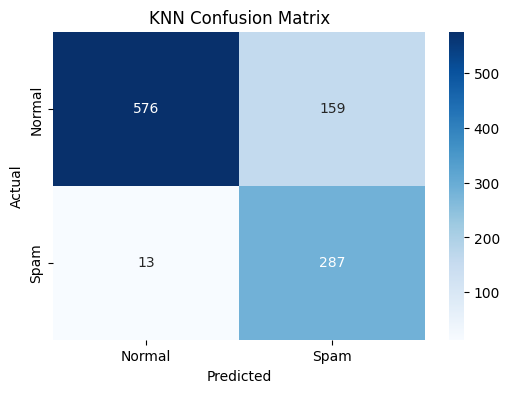

In [13]:
print("KNN CLASSIFICATION REPORT")

print(classification_report(
    Y_test,
    knn_predictions,
    target_names=['Normal', 'Spam']
))

# Confusion Matrix
knn_cm = confusion_matrix(Y_test, knn_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Spam'],
    yticklabels=['Normal', 'Spam']
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



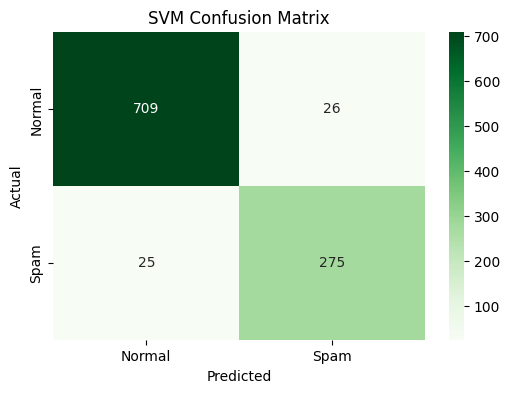

In [14]:
print("SVM CLASSIFICATION REPORT")

print(classification_report(
    Y_test,
    svm_predictions,
    target_names=['Normal', 'Spam']
))

# Confusion Matrix
svm_cm = confusion_matrix(Y_test, svm_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Normal', 'Spam'],
    yticklabels=['Normal', 'Spam']
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [15]:
def evaluate_model(name, actual, predicted):

    return {
        'Model': name,
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted),
        'Recall': recall_score(actual, predicted),
        'F1 Score': f1_score(actual, predicted)
    }


# Evaluate both models
knn_results = evaluate_model(
    'KNN',
    Y_test,
    knn_predictions
)

svm_results = evaluate_model(
    'SVM',
    Y_test,
    svm_predictions
)

# Comparison table
results = pd.DataFrame([
    knn_results,
    svm_results
])

print("MODEL PERFORMANCE COMPARISON")

display(results)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.833816,0.643498,0.956667,0.769437
1,SVM,0.950725,0.913621,0.916667,0.915141


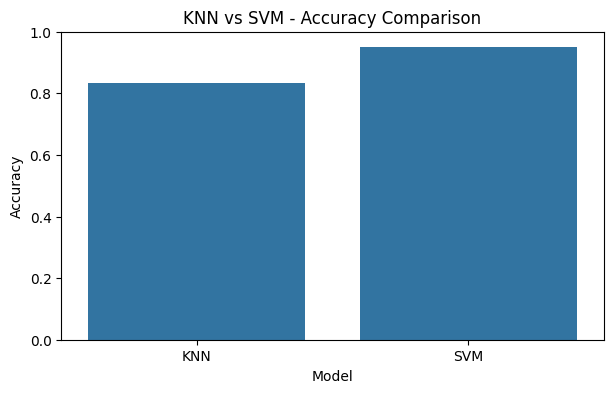

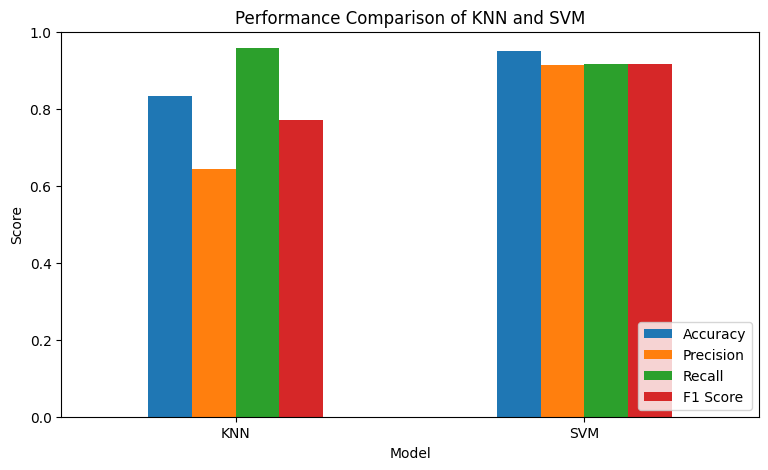

In [16]:
# Compare model accuracy
plt.figure(figsize=(7, 4))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("KNN vs SVM - Accuracy Comparison")
plt.ylim(0, 1)
plt.show()


# Compare all performance metrics
results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(9, 5))

plt.title("Performance Comparison of KNN and SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [17]:
best_model = results.loc[
    results['F1 Score'].idxmax()
]

print("Best Performing Model:", best_model['Model'])

print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))

Best Performing Model: SVM
Accuracy: 0.9507
Precision: 0.9136
Recall: 0.9167
F1 Score: 0.9151


In [18]:
# Select one email from test dataset
sample_email = X_test.iloc[[0]]

# Actual category
actual = Y_test.iloc[0]

# Predictions
knn_result = knn_model.predict(sample_email)[0]
svm_result = svm_model.predict(sample_email)[0]

# Display results
labels = {
    0: "Normal Email (Not Spam)",
    1: "Spam Email"
}

print("Actual Email Category:", labels[actual])

print("KNN Prediction:", labels[knn_result])

print("SVM Prediction:", labels[svm_result])

Actual Email Category: Normal Email (Not Spam)
KNN Prediction: Normal Email (Not Spam)
SVM Prediction: Normal Email (Not Spam)
